# SHAP Summary Plot

## Исходные данные для построения

In [10]:
# Настройка отображения
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.width', None)
pd.set_option('display.max_columns', None)

Как сохранить:   
`X_test.to_csv('X_test.csv', index=False)`  
`np.save('shap_values.npy', shap_values)`  

In [15]:
#shap_values = np.load('shap_values.npy')
model = joblib.load('model.pkl')
X_test = pd.read_csv('X_test.csv')

In [19]:
model

RandomForestClassifier(class_weight='balanced', max_depth=6,
                       min_samples_leaf=30, n_estimators=500, random_state=42)

In [11]:
print(X_test)

      Frequency  Monetary     Avg_Check  Avg_Days_Between_Purchases  Frequency_Delta  Monetary_Delta  Frequency_Growth  Monetary_Growth
0           0.0       0.0      0.000000                         0.0              0.0             0.0               0.0         0.000000
1           1.0    1351.0   1351.000000                         0.0              0.0             0.0               1.0         1.000000
2           2.0     713.0    356.500000                       163.0              1.0            64.0               2.0         1.098613
3           2.0    2262.0   1131.000000                        54.5              0.0             0.0               1.0         1.000000
4           2.0     799.0    399.500000                       132.0              1.0           198.0               2.0         1.329451
...         ...       ...           ...                         ...              ...             ...               ...              ...
4776        2.0    1498.0    749.000000         

## Код для построения

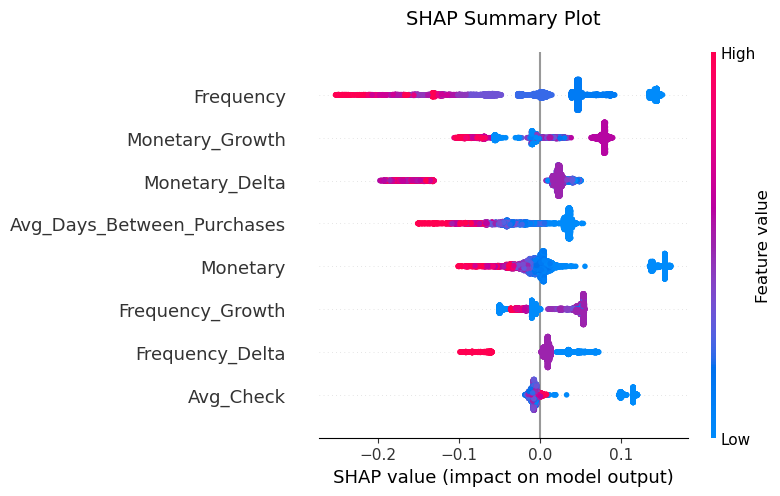

In [16]:
# =====================================================
# IMPORTS
# =====================================================

import joblib
import pandas as pd
import shap
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# LOAD DATA
# =====================================================

#shap_values = np.load('shap_values.npy')
X_test = pd.read_csv('X_test.csv')

# =====================================================
# SHAP EXPLAINER
# =====================================================

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test)

# =====================================================
# GLOBAL SHAP IMPORTANCE
# =====================================================

shap.summary_plot(
    shap_values[:, :, 1],
    X_test, show=False
)
plt.title("SHAP Summary Plot", fontsize=14, pad=20)
# plt.savefig("shap_summary_plot.png", bbox_inches='tight', dpi=300)

#plt.close()
plt.show()

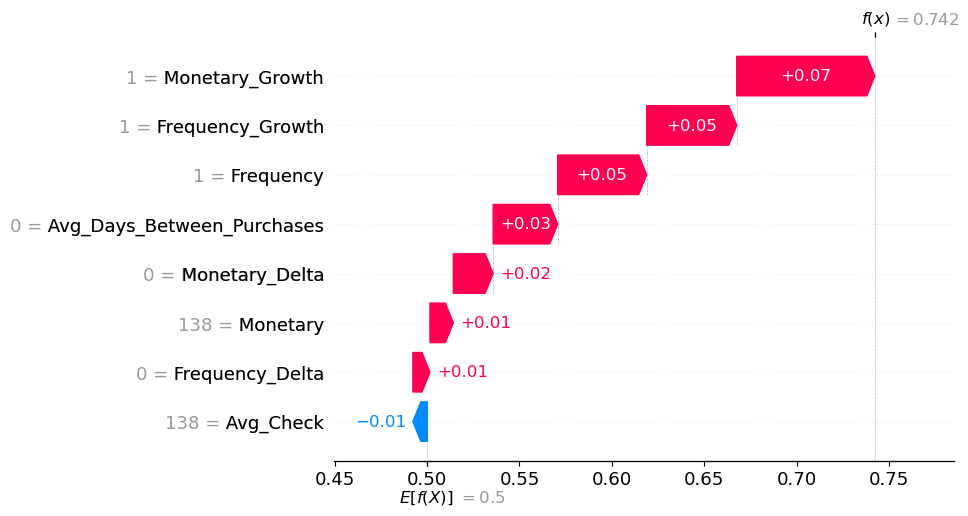

In [17]:
# =====================================================
# SINGLE CUSTOMER EXPLANATION
# =====================================================

customer_idx = 10

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[:, :, 1][customer_idx],
        base_values=explainer.expected_value[1],
        data=X_test.iloc[customer_idx],
        feature_names=X_test.columns
    )
)

In [18]:
print(shap_values)

[[[-1.43652360e-01  1.43652360e-01]
  [-1.53499581e-01  1.53499581e-01]
  [-1.14454513e-01  1.14454513e-01]
  ...
  [-2.30337655e-02  2.30337655e-02]
  [ 1.05336057e-02 -1.05336057e-02]
  [ 9.88647549e-03 -9.88647549e-03]]

 [[-4.50510351e-02  4.50510351e-02]
  [ 7.56900063e-03 -7.56900063e-03]
  [ 8.29468635e-03 -8.29468635e-03]
  ...
  [-2.16487464e-02  2.16487464e-02]
  [-5.27857337e-02  5.27857337e-02]
  [-7.87696938e-02  7.87696938e-02]]

 [[ 2.24880480e-02 -2.24880480e-02]
  [-1.18256414e-03  1.18256414e-03]
  [ 7.28384605e-03 -7.28384605e-03]
  ...
  [ 1.71915074e-01 -1.71915074e-01]
  [ 3.00676601e-02 -3.00676601e-02]
  [ 9.39940485e-02 -9.39940485e-02]]

 ...

 [[-4.53863931e-02  4.53863931e-02]
  [ 5.91337397e-05 -5.91337397e-05]
  [ 8.51952378e-03 -8.51952378e-03]
  ...
  [-2.14546341e-02  2.14546341e-02]
  [-5.28686215e-02  5.28686215e-02]
  [-7.82250430e-02  7.82250430e-02]]

 [[-1.73780428e-03  1.73780428e-03]
  [ 3.86863476e-03 -3.86863476e-03]
  [ 8.43848810e-03 -8.4384